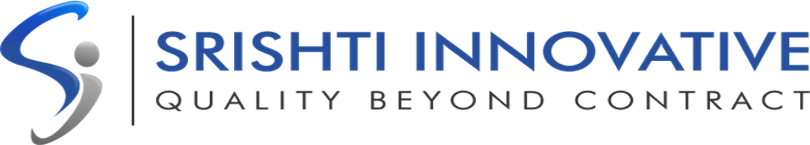

# **EDA on Diabetes Dataset**

The Pima Indians Diabetes dataset contains health measurements of female patients (like glucose, blood pressure, BMI, age) to predict whether they have diabetes.

It is widely used for binary classification and EDA, with numeric features and a target column (Outcome) indicating diabetes presence (1) or absence (0).

# **Import libraries**

In [ ]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# **Load Dataset**

In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columns = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv(url, names=columns)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


We specify columns while loading the dataset so that each column has a meaningful name, making the data easier to read, understand, and analyze.



If we don’t provide column names, Pandas assigns default numeric headers (0, 1, 2…), which are confusing and make EDA and teaching harder.

**Columns and Overview**

In [ ]:
# Column info
print("Columns:", df.columns.tolist())

Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


- **Pregnancies**: Number of times the patient has been pregnant.  
- **Glucose**: Plasma glucose concentration after a 2-hour oral glucose tolerance test.  
- **BloodPressure**: Diastolic blood pressure (mm Hg).  
- **SkinThickness**: Triceps skinfold thickness (mm), measures body fat.  
- **Insulin**: 2-hour serum insulin (mu U/ml).  
- **BMI**: Body Mass Index (weight in kg / height in m²).  
- **DiabetesPedigreeFunction**: Diabetes pedigree function; a score that represents family history of diabetes.  
- **Age**: Age of the patient (years).  
- **Outcome**: Target variable, 1 indicates diabetes, 0 indicates no diabetes.


**Shape of dataset**

In [ ]:
df.shape

(768, 9)

df.shape returns (768, 9) →

* 768 rows → number of patients in the dataset

* 9 columns → 8 features + 1 target (Outcome)

**Summary statistics**

In [ ]:
# Summary statistics
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


- The dataset has **768 samples** with 8 numeric features and 1 target (`Outcome`), where some features (Glucose, BloodPressure, BMI, Insulin) have **0 values indicating missing data**.  
- Features like Glucose, BMI, and Age show wide ranges and variation, while the target (`Outcome`) is binary with ~35% positive cases.

**Handling Missing Values**

In [ ]:
# Check for missing values
print("Missing values:\n", df.isnull().sum())

Missing values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


- The dataset now shows **no missing values**.

Even though our code showed '0' missing values earlier, we discovered through our summary statistics that several columns have a minimum value of 0. For features like Glucose, BloodPressure, BMI, and Insulin, a value of zero is medically impossible for a living person. In data science, these are called 'hidden' missing values because they are represented by a number instead of an empty cell.

**Handle these hidden zeros**

In [ ]:
#replace these '0' values with NaN
df[['Glucose','BloodPressure','BMI','Insulin']] = df[['Glucose','BloodPressure','BMI','Insulin']].replace(0, np.nan)

In [ ]:
# Check for missing values
print("Missing values:\n", df.isnull().sum())

Missing values:
 Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness                 0
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
# Fill NaN values with the median of each column
df["Glucose"] = df["Glucose"].fillna(df["Glucose"].median())
df["BloodPressure"] = df["BloodPressure"].fillna(df["BloodPressure"].median())
df["SkinThickness"] = df["SkinThickness"].fillna(df["SkinThickness"].median())
df["Insulin"] = df["Insulin"].fillna(df["Insulin"].median())
df["BMI"] = df["BMI"].fillna(df["BMI"].median())

In [ ]:
#Verify that all missing values are gone
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


**Checking for Duplicate Values**

In [ ]:
# Check for duplicate rows
duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)


Number of duplicate rows: 0


In the Pima Indians Diabetes dataset, there are no duplicates.

**Detect outliers using IQR**

In [ ]:
# Detect outliers using IQR
outlier_info = {}
for col in df.columns[:-1]:  # Exclude target
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 1.5*IQR)) | (df[col] > (Q3 + 1.5*IQR))]
    outlier_info[col] = outliers.shape[0]

outlier_info


{'Pregnancies': 4,
 'Glucose': 0,
 'BloodPressure': 14,
 'SkinThickness': 1,
 'Insulin': 346,
 'BMI': 8,
 'DiabetesPedigreeFunction': 29,
 'Age': 9}

- The dictionary shows the **number of outliers detected in each feature** using the IQR method.  
- Features like `BloodPressure`, `Insulin`, and `DiabetesPedigreeFunction` have a higher number of outliers, indicating **extreme values that may affect analysis or modeling**.


**Using Boxplots**

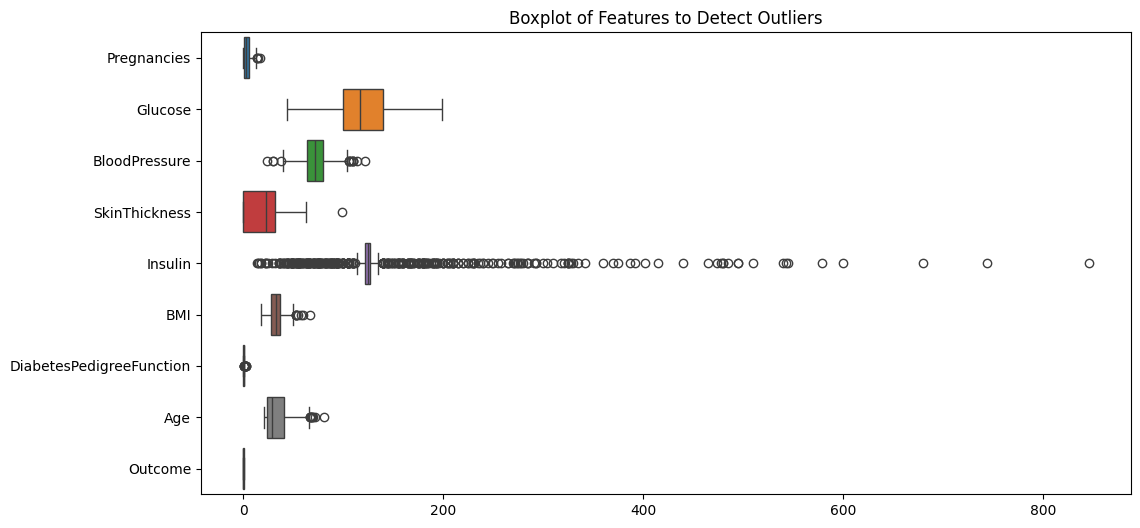

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, orient='h')
plt.title("Boxplot of Features to Detect Outliers")
plt.show()

Each boxplot shows the interquartile range (IQR) and points outside it (outliers).

Features like Insulin, SkinThickness, Glucose, and BMI usually show some extreme values.

**Removing Outliers**

In [ ]:
# Remove outliers using IQR method
df_clean = df.copy()  # Create a copy to preserve original

for col in df_clean.columns[:-1]:  # Exclude target
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    df_clean = df_clean[(df_clean[col] >= (Q1 - 1.5*IQR)) & (df_clean[col] <= (Q3 + 1.5*IQR))]

# Check new shape
df_clean.shape


(358, 9)

- After removing outliers, the dataset now has **358 rows and 9 columns**, showing that extreme values were successfully removed.  
- This cleaned dataset is now **more reliable for analysis and modeling**, with reduced skew from extreme feature values.


# **Target Variable Analysis**

In [ ]:
# Count of each class in Outcome
outcome_counts = df_clean['Outcome'].value_counts()
outcome_counts

,count
Outcome,
0,230
1,128


- `Outcome = 0` → Number of patients **without diabetes**.  
- `Outcome = 1` → Number of patients **with diabetes**.  

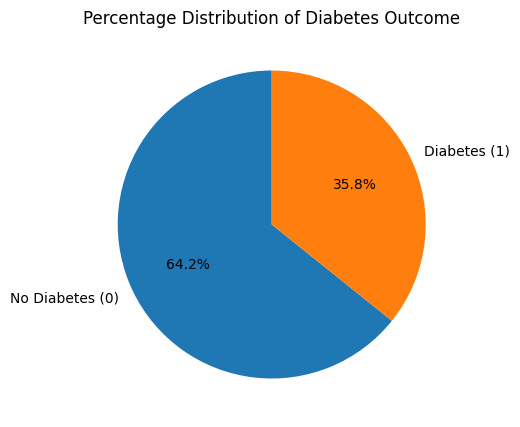

In [ ]:
outcome_counts = df_clean['Outcome'].value_counts()

plt.figure(figsize=(5,5))
plt.pie(
    outcome_counts,
    labels=['No Diabetes (0)', 'Diabetes (1)'],
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Percentage Distribution of Diabetes Outcome")
plt.show()

# **Distribution of Glucose**

### Glucose Distribution
- Shows how blood glucose levels are spread across patients.
- Helps identify common glucose ranges and extreme values.

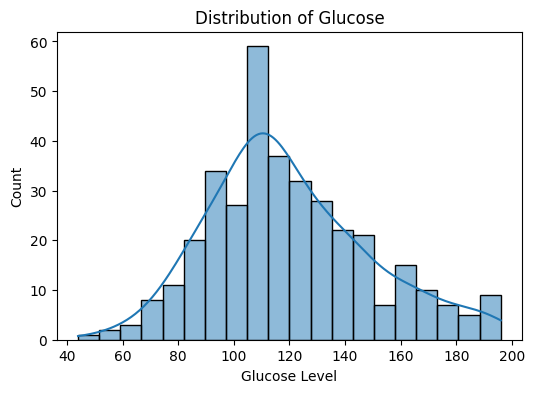

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(df_clean['Glucose'], bins=20, kde=True)
plt.title("Distribution of Glucose")
plt.xlabel("Glucose Level")
plt.ylabel("Count")
plt.show()


# **Distribution of BMI**

### BMI Distribution
- Indicates body mass index spread among patients.
- Useful to observe obesity patterns related to diabetes.


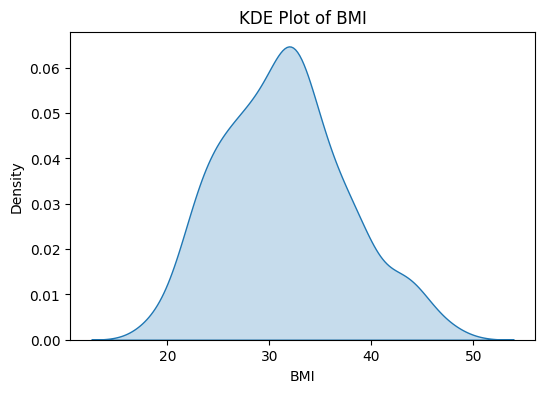

In [ ]:
plt.figure(figsize=(6,4))
sns.kdeplot(df_clean['BMI'], fill=True)
plt.title("KDE Plot of BMI")
plt.xlabel("BMI")
plt.ylabel("Density")
plt.show()



# **BMI vs Glucose**

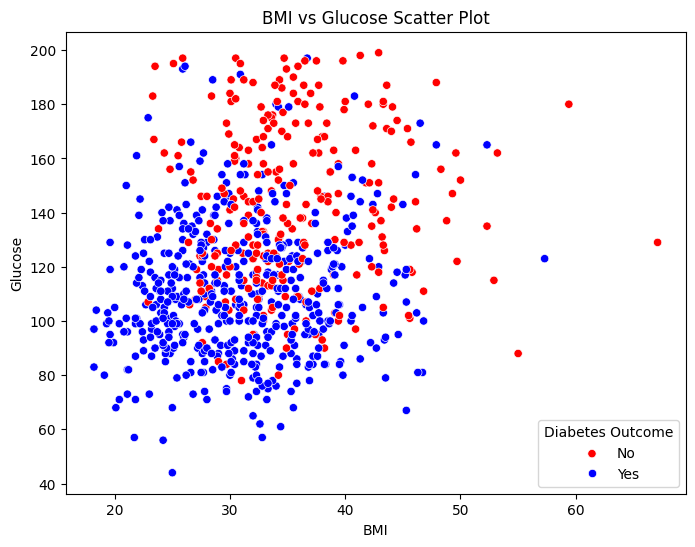

In [ ]:
# Scatter plot of BMI vs Glucose
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='BMI', y='Glucose', hue='Outcome', palette={0:'blue', 1:'red'})
plt.title('BMI vs Glucose Scatter Plot')
plt.xlabel('BMI')
plt.ylabel('Glucose')
plt.legend(title='Diabetes Outcome', labels=['No', 'Yes'])
plt.show()

Red points (diabetic) are generally higher in Glucose and BMI, showing a positive relationship.

# **BMI vs Diabetes Outcome**

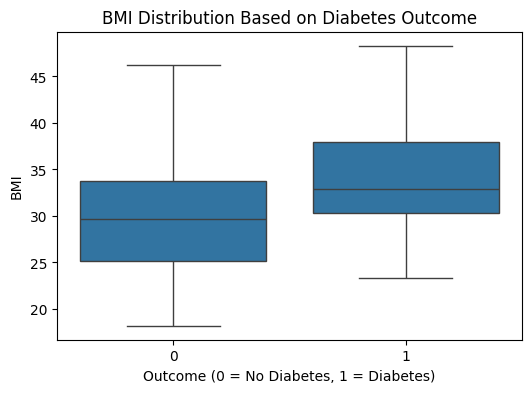

In [ ]:
plt.figure(figsize=(6,4))
sns.boxplot(x='Outcome', y='BMI', data=df_clean)
plt.title("BMI Distribution Based on Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("BMI")
plt.show()


Diabetic patients generally have a higher BMI compared to non-diabetic patients.

The box plot shows variability and presence of extreme BMI values across both classes.

# **BMI vs Age**

In [ ]:
grouped_data = df_clean.groupby('Outcome')[['Age', 'BMI']].mean()
grouped_data

,Age,BMI
Outcome,,
0,33.395652,29.962609
1,38.132812,34.170313


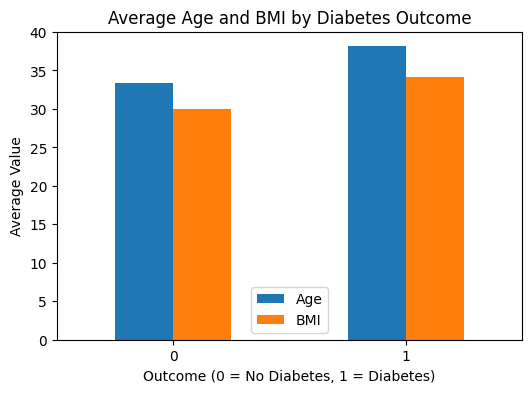

In [ ]:
grouped_data.plot(kind='bar', figsize=(6,4))
plt.title("Average Age and BMI by Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.show()


Older individuals with higher BMI tend to have a higher risk of diabetes. Age moderately influences diabetes risk when combined with BMI.

# **Feature Distribution Analysis**

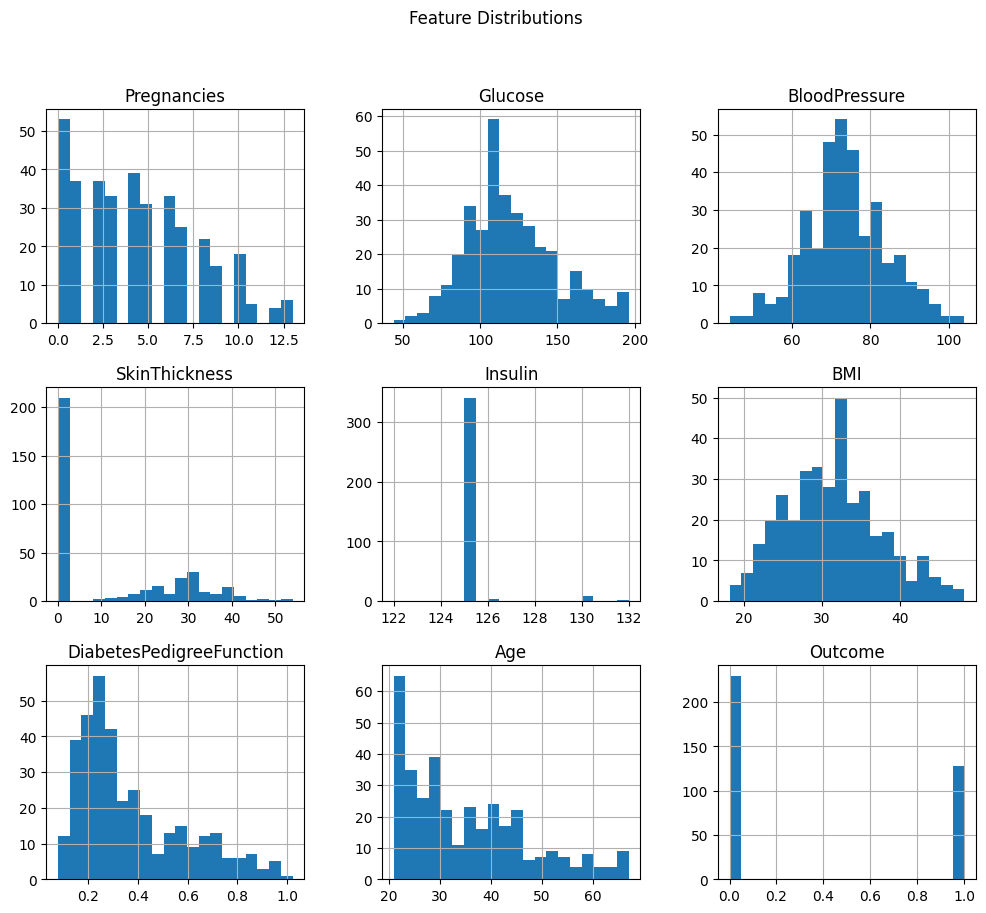

In [ ]:
# Histogram for all features
df_clean.hist(figsize=(12,10), bins=20)
plt.suptitle("Feature Distributions")
plt.show()

Several features such as insulin, pregnancies, and blood pressure show varied distributions with some outliers. Glucose and BMI are the most indicative features of diabetes.

# **Correlation Matrix**

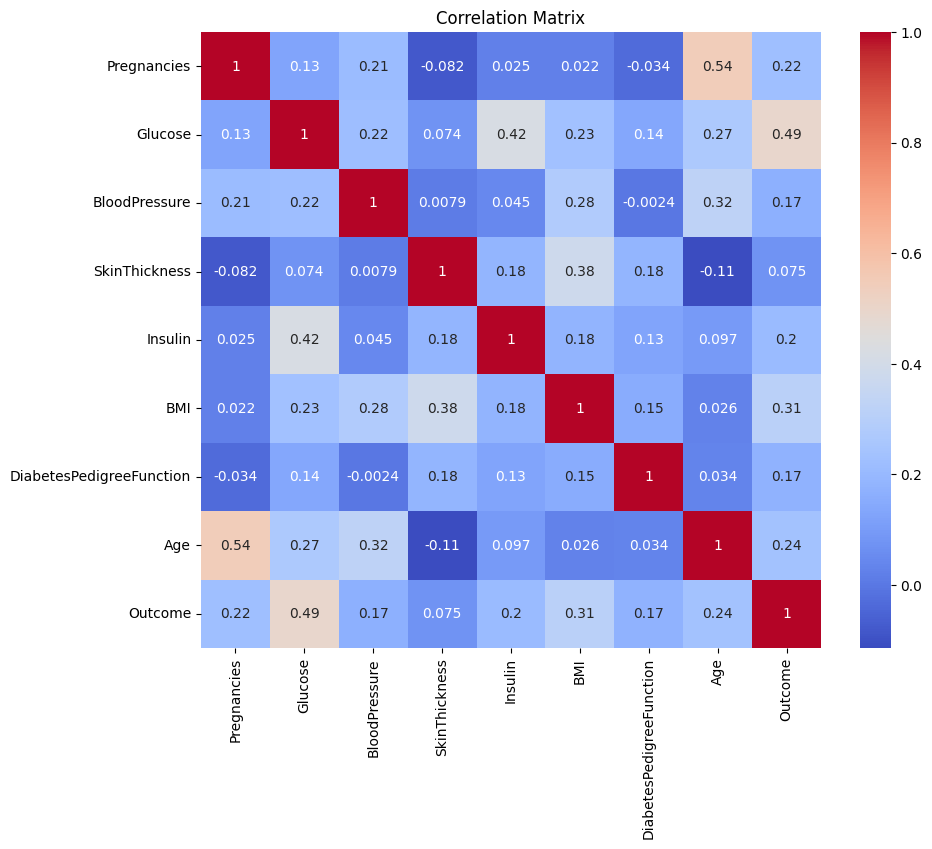

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

Glucose and BMI show the strongest positive correlation with the target variable. Other features like age and pregnancies show mild correlation. Blood pressure and insulin have lower direct correlation but may contribute in combination with other factors.

# **Key Insight**



Glucose and BMI are the strongest indicators of diabetes in this dataset.

Age and Pregnancies provide additional context but are less decisive alone.

Outliers and feature distributions suggest careful preprocessing is required before modeling.

Combining multiple features improves predictive power compared to using a single feature.